# Inland Excess Water (IEW) Monitoring — Prithvi-EO-2.0 + UPerNet

**Notebook 13. A pre-trained geospatial *foundation model* (Vision Transformer) as the encoder.**

### Where this fits

| Notebook | Bet | Result (test, raw) |
|---|---|---|
| 10 Spectral ResUNet | Small CNN, spectral branch, rare-class sampling | macro-F1 75.57, classes 2–6 F1 80.50 |
| 11 Temporal-Radar Former | Multi-date transformer trained from scratch | macro-F1 75.59, classes 2–6 F1 80.30 |
| 12 PT-UPerNet | ResNet-50s pre-trained on Sentinel + terrain | not yet validly run |
| **13 Prithvi-EO-2.0** | **A 300 M-parameter ViT pre-trained by NASA/IBM on 4.2 M Harmonized Landsat-Sentinel (HLS) samples, multi-temporal** | **this notebook** |

Notebooks 10 and 11 landed at the same score although they are very different networks. That suggests the limit is not the network shape but how much *visual knowledge* a model can learn from only 12 labelled training scenes. A foundation model brings that knowledge from outside.

### What Prithvi-EO-2.0 is

- A **Vision Transformer (ViT)**, 24 blocks, width 1024, about 300 M parameters, pre-trained as a **masked autoencoder** (hide most patches, rebuild them) on 4.2 M samples of six bands: **Blue, Green, Red, narrow NIR, SWIR-1, SWIR-2**.
- **Multi-temporal by design.** A 3-D patch embedding takes a stack of frames `(bands, T, H, W)` with `T = 4` and 16×16 patches. Attention runs over *all* patches of *all* frames, so a patch in the target date can attend to the same place on earlier dates.
- Apache-2.0 licensed. Weights are downloaded from Hugging Face by the TerraTorch library.

### How it is used here

```
 target date + up to 3 earlier dates (same site, chronological, target LAST)
     6 HLS-equivalent S2 bands per date  ───►  Prithvi-EO-2.0 (300M ViT)
     (our B02 B03 B04 B8A B11 B12)               tokens from blocks 6, 12, 18, 24
                                                       │ keep target-date tokens + temporal mean
                                                       ▼
                                   simple feature pyramid (1/4, 1/8, 1/16, 1/32) ── UPerNet decoder (256 ch @ 1/4)
                                                                                         │
 target date, full detail:  S2 (11 bands + 6 indices + cloud score)                      │
                            S1 (VV, VH, ratio)  ───► small CNN branch (1/1, 1/2, 1/4) ───┤ skip connections
                                                                                         ▼
                                              refine to full resolution ──► main (6) / coarse (4) / ordinal (soil severity)
```

- **Why a CNN branch next to the ViT.** Prithvi sees only six optical bands, at 1/16 resolution. The CNN branch brings back what it cannot see: Sentinel-1 radar (zeroing radar cost notebook 11 about 8 F1 points), the other optical bands, and fine spatial detail.
- **Missing dates.** Prithvi needs exactly 4 frames. If a scene has fewer than 3 earlier dates, the oldest available frame is repeated at the front. In 8 of 23 scenes there are none, so the target date is repeated 4 times.
- **Same outputs as notebooks 11 and 12:** a flat 6-class head, a coarse 4-class head, and an ordinal soil-severity head, blended and evaluated with the same protocol.

### Training for a 6 GB GPU

A 300 M-parameter model cannot be fully fine-tuned in 6 GB with AdamW. So:

| Phase | What trains |
|---|---|
| Epochs 1–`FREEZE_EPOCHS` | Only the new decoder and CNN branch. Prithvi is completely frozen. Because no frozen weight needs a gradient, no activations are stored for it. |
| Afterwards | Decoder/CNN at `HEAD_LR`, plus the **last `UNFREEZE_LAST_BLOCKS` Prithvi blocks** and its final norm at `BACKBONE_LR` (10× smaller) |

Checkpoints and the EMA copy store only the trainable part, not the frozen 1.2 GB of Prithvi weights, so they stay small.

### Honest expectations

Four different networks have now plateaued near 76 macro-F1 on the test set, so a gain from a new encoder alone is **not guaranteed**. A realistic hope is a few points on the soil classes. **90+ F1 on every class is unlikely**, because the serious/moderate/slight boundaries in the labels are themselves fuzzy and the scene-to-scene variation (scene scores ranged from 57 to 82 in notebook 11) is larger than any difference between models. This notebook reports raw, blended and calibrated scores side by side so you can see what each step really contributes. Calibration hurt on test in notebook 11, so **trust the raw and blended rows first**.

### How to run

1. **Environment.** Use a *separate* Python environment from notebooks 11 and 12, because TerraTorch pins many dependencies. Install: `pip install terratorch rasterio pyyaml matplotlib` plus a CUDA build of PyTorch. This code was written against the TerraTorch source and the Hugging Face model card but has **never been executed**, so expect the first dry run to reveal small fixes.
2. **Internet** is needed once, for the ≈1.2 GB weight download from Hugging Face.
3. **Dataset path:** `dataset_root` in `configs/data.yaml`.
4. **Dry run first:** set `QUICK_TEST = True` and run all cells. If it finishes, set `QUICK_TEST = False`, restart the kernel, and run all cells. If you ran notebook 12 with `QUICK_TEST` before, remember that stale outputs stay in a notebook until the cells are re-run.
5. **Memory:** defaults are `PATCH = 224`, `BATCH_SIZE = 4`, `ACCUM_STEPS = 2` (effective batch 8). If you get *CUDA out of memory*, set `BATCH_SIZE = 2` and `ACCUM_STEPS = 4`, and/or `UNFREEZE_LAST_BLOCKS = 2`.
6. **Interruptions:** a checkpoint is saved every epoch and training resumes automatically.

### Outputs

- `outputs/checkpoints/prithvi_best.pt`, `prithvi_last.pt`: trainable weights only
- `outputs/checkpoints/prithvi_calibration.json`: blend weight and per-class bias
- `outputs/prithvi_results.json`: all test metrics, per-scene scores, ablation
- `outputs/preds_prithvi/<scene>.npy`: predicted label maps (raw / blend / calibrated) for later ensembling or error analysis

## 1. Imports and configuration

In [13]:
import contextlib
import datetime
import json
import math
import time
from pathlib import Path

import numpy as np
import yaml
import rasterio
from rasterio.windows import Window
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

QUICK_TEST = False          # True = tiny dry run of the whole notebook (writes *_quicktest* files only)

SEED         = 0
PATCH        = 224          # must be divisible by the Prithvi patch size (16 for 300M, 14 for 600M)
GRID_STRIDE  = 56
N_FRAMES     = 4            # Prithvi-EO-2.0 was pre-trained with 4 frames
MAX_GAP_DAYS = 120
CONTEXT_DROPOUT = 0.3       # training: drop each earlier date with this probability
GAIN_JITTER  = 0.05
BATCH_SIZE   = 4
ACCUM_STEPS  = 2            # effective batch = BATCH_SIZE * ACCUM_STEPS
NUM_WORKERS  = 0            # keep 0 on Windows + Jupyter
USE_AMP      = True
RESUME       = True

BACKBONE             = "prithvi_eo_v2_300"     # or "prithvi_eo_v2_600" (needs more memory)
PRETRAINED           = True
UNFREEZE_LAST_BLOCKS = 4
FREEZE_EPOCHS        = 3

EPOCHS            = 25
SAMPLES_PER_EPOCH = 2000
VAL_PATCHES       = 300
HEAD_LR           = 5e-4
BACKBONE_LR       = 5e-5
WEIGHT_DECAY      = 0.05
WARMUP_FRAC       = 0.05
EMA_DECAY         = 0.999
ORDINAL_SMOOTH    = 0.10

TILE, MARGIN = 160, 32      # inference windows are exactly PATCH: TILE + 2*MARGIN == PATCH
INFER_BATCH  = 8
TTA          = "flip"       # "none" | "flip" | "d4" (d4 is 8x slower)

VAL_SCENES  = ["BNPI_20230208", "KNPI_20220310"]       # same as notebooks 10, 11 and 12
CLASS_SHARE = {0: 0.05, 1: 0.20, 2: 0.20, 3: 0.10, 4: 0.10}

MAX_TILES = None
if QUICK_TEST:
    EPOCHS, FREEZE_EPOCHS, SAMPLES_PER_EPOCH, VAL_PATCHES = 2, 1, 16, 8
    TTA, MAX_TILES = "none", 4

VARIANTS = {"prithvi_eo_v2_300": dict(embed=1024, depth=24, patch=16),
            "prithvi_eo_v2_600": dict(embed=1280, depth=32, patch=14)}
assert BACKBONE in VARIANTS, f"BACKBONE must be one of {list(VARIANTS)} (the TL variants need coordinates, not supported here)"
V = VARIANTS[BACKBONE]
assert PATCH % V["patch"] == 0 and PATCH % 4 == 0, f"PATCH must be divisible by {V['patch']}"
assert TILE + 2 * MARGIN == PATCH, "TILE + 2*MARGIN must equal PATCH (Prithvi is built for one fixed image size)"

TAG       = "prithvi" + ("_quicktest" if QUICK_TEST else "")
CKPT_DIR  = Path("outputs/checkpoints")
CKPT_DIR.mkdir(parents=True, exist_ok=True)
BEST_PATH = CKPT_DIR / f"{TAG}_best.pt"
LAST_PATH = CKPT_DIR / f"{TAG}_last.pt"
CAL_PATH  = CKPT_DIR / f"{TAG}_calibration.json"
RESULTS_PATH = Path("outputs") / f"{TAG}_results.json"
PRED_DIR  = Path("outputs") / f"preds_{TAG}"
PRED_DIR.mkdir(parents=True, exist_ok=True)

torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_ON = USE_AMP and device.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (AMP_ON and torch.cuda.is_bf16_supported()) else torch.float16
if device.type == "cuda":
    torch.backends.cudnn.benchmark = True
    print(f"GPU: {torch.cuda.get_device_name(0)} | "
          f"{torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GB")
else:
    print("WARNING: no CUDA GPU found - this notebook is meant for a GPU. Use QUICK_TEST only on CPU.")
print(f"PyTorch {torch.__version__} | device {device} | AMP {AMP_ON} ({AMP_DTYPE if AMP_ON else '-'})")


def autocast():
    return torch.autocast(device_type=device.type, dtype=AMP_DTYPE, enabled=AMP_ON)


def make_scaler():
    enabled = AMP_ON and AMP_DTYPE == torch.float16
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=enabled)

GPU: NVIDIA GeForce RTX 4050 Laptop GPU | 6.0 GB
PyTorch 2.6.0+cu124 | device cuda | AMP True (torch.bfloat16)


## 2. Data: scenes, timeline, and the two input streams

Each sample has two inputs and a label:

- **`pv` (Prithvi stream), shape `(6, 4, P, P)`.** The six HLS-equivalent bands in Prithvi's order: our **B02 (blue), B03 (green), B04 (red), B8A (narrow NIR), B11 (SWIR-1), B12 (SWIR-2)** = band indices `[1, 2, 3, 8, 9, 10]` of the 11-band file. They are normalised with Prithvi's own statistics (digital-number scale, the same ×10000 reflectance scale as our files): mean `[1087, 1342, 1433, 2734, 1958, 1363]`, std `[2248, 2179, 2178, 1850, 1242, 1049]`. Frames are in **chronological order with the target date last**. Missing earlier dates are filled by repeating the oldest available frame. No-data pixels are set to 0 after normalisation (the mean).
- **`cnn` (detail stream), shape `(23, P, P)`**, target date only: 11 standardised S2 bands, 6 spectral indices, a cloud/haze score, an S2 valid flag, 3 standardised S1 channels and an S1 valid flag. This is the same feature set as notebook 11.
- Earlier dates come from the same per-site timeline as notebook 11 (same pixel grid, within `MAX_GAP_DAYS`). Only their **imagery** is read; their labels are never touched.

In [14]:
with open("configs/data.yaml", "r") as f:
    config = yaml.safe_load(f)

dataset_root = Path(config["dataset_root"])
LOCAL_ROOT = Path("C:/E/S5/Deep_Learning/dataset/tifs_FINAL")
if not dataset_root.exists() and LOCAL_ROOT.exists():
    dataset_root = LOCAL_ROOT
assert dataset_root.exists(), f"Dataset not found at {dataset_root} - edit dataset_root in configs/data.yaml"
print(f"Dataset root: {dataset_root}")

IGNORE = 255
NUM_CLASSES = 6
CLASS_NAMES = [
    "Open surface water (raw 2)",
    "Soil seriously affected (raw 3)",
    "Soil moderately affected (raw 4)",
    "Soil slightly affected (raw 5)",
    "Vegetation affected (raw 6)",
    "Not affected (raw 7)",
]
GT_LUT = np.full(256, IGNORE, dtype=np.uint8)
for raw, cls in {2: 0, 3: 1, 4: 2, 5: 3, 6: 4, 7: 5}.items():
    GT_LUT[raw] = cls

# Band order of the 11-band files: B01 B02 B03 B04 B05 B06 B07 B08 B8A B11 B12
S2_MEAN = np.array([0.0436, 0.0557, 0.0723, 0.0838, 0.1151, 0.1598,
                    0.1800, 0.1974, 0.2004, 0.2233, 0.1706], dtype=np.float32)
S2_STD  = np.array([0.0182, 0.0233, 0.0272, 0.0340, 0.0380, 0.0598,
                    0.0686, 0.0751, 0.0728, 0.0674, 0.0606], dtype=np.float32)
S1_MEAN = np.array([-21.6081, -13.6686, -8.0403], dtype=np.float32)
S1_STD  = np.array([3.4706, 3.0644, 2.5309], dtype=np.float32)

# Prithvi-EO-2.0 input: Blue, Green, Red, narrow NIR, SWIR-1, SWIR-2  (pre-training statistics, DN scale)
PV_BANDS = [1, 2, 3, 8, 9, 10]
PV_MEAN = np.array([1087.0, 1342.0, 1433.0, 2734.0, 1958.0, 1363.0], dtype=np.float32)
PV_STD  = np.array([2248.0, 2179.0, 2178.0, 1850.0, 1242.0, 1049.0], dtype=np.float32)

CNN_CH = 11 + 6 + 1 + 1 + 3 + 1       # 23


def s2_features(s2_raw: np.ndarray) -> np.ndarray:
    """(11,H,W) raw S2 DN -> (19,H,W): standardised bands, indices, cloud score, valid flag."""
    s2 = s2_raw.astype(np.float32)
    valid = np.isfinite(s2).all(0)
    s2 = np.nan_to_num(s2, nan=0.0, posinf=0.0, neginf=0.0) / 10000.0
    valid &= s2.sum(0) > 0
    eps = 1e-6
    blue, green, red, nir, nir_n, swir1, swir2 = s2[1], s2[2], s2[3], s2[7], s2[8], s2[9], s2[10]
    indices = np.stack([
        (nir - red) / (nir + red + eps),
        (nir_n - swir1) / (nir_n + swir1 + eps),
        (green - nir) / (green + nir + eps),
        (green - swir1) / (green + swir1 + eps),
        (swir1 - red) / (swir1 + red + eps),
        (swir1 - swir2) / (swir1 + swir2 + eps),
    ]) * 2.0
    cloud = np.clip((np.minimum(blue, red) - 0.10) / 0.20, 0.0, 1.0)
    s2n = (s2 - S2_MEAN[:, None, None]) / S2_STD[:, None, None]
    x = np.concatenate([s2n, indices, cloud[None]], axis=0)
    x = np.clip(np.nan_to_num(x, nan=0.0, posinf=6.0, neginf=-6.0), -6.0, 6.0)
    v = valid.astype(np.float32)
    return np.concatenate([x * v[None], v[None]], axis=0).astype(np.float32)


def s1_features(s1_raw: np.ndarray) -> np.ndarray:
    """(3,H,W) S1 dB -> (4,H,W): standardised channels + valid flag."""
    s1 = s1_raw.astype(np.float32)
    valid = np.isfinite(s1).all(0)
    s1 = np.nan_to_num(s1, nan=0.0, posinf=0.0, neginf=0.0)
    valid &= np.abs(s1[0]) > 1e-6
    s1n = np.clip((s1 - S1_MEAN[:, None, None]) / S1_STD[:, None, None], -6.0, 6.0)
    v = valid.astype(np.float32)
    return np.concatenate([s1n * v[None], v[None]], axis=0).astype(np.float32)


def prithvi_frame(s2_raw: np.ndarray) -> np.ndarray:
    """(11,H,W) raw S2 DN -> (6,H,W) in Prithvi's band order, normalised with its pre-training statistics."""
    s2 = s2_raw.astype(np.float32)
    valid = np.isfinite(s2).all(0)
    s2 = np.nan_to_num(s2, nan=0.0, posinf=0.0, neginf=0.0)
    valid &= s2.sum(0) > 0
    x = (s2[PV_BANDS] - PV_MEAN[:, None, None]) / PV_STD[:, None, None]
    return (np.clip(x, -10.0, 10.0) * valid[None]).astype(np.float32)


class Scene:
    """One acquisition (site + date). S2/S1 are read by window; GT is loaded lazily and only if asked for."""

    def __init__(self, split: str, split_dir: Path, filename: str):
        self.name = Path(filename).stem
        self.split = split
        self.site, date_str = self.name.split("_")[:2]
        self.date = datetime.datetime.strptime(date_str, "%Y%m%d").date()
        self.s2_path = split_dir / "S2" / filename
        self.s1_path = split_dir / "S1" / filename
        self.gt_path = split_dir / "GT" / filename
        if not self.s1_path.exists():
            raise FileNotFoundError(f"Missing file: {self.s1_path}")
        with rasterio.open(self.s2_path) as src:
            self.H, self.W, self.transform = src.height, src.width, src.transform
        with rasterio.open(self.s1_path) as src:
            assert (src.height, src.width) == (self.H, self.W), f"S1/S2 size mismatch in {self.name}"
        self._gt = None
        self._s2 = None
        self._s1 = None

    @property
    def gt(self) -> np.ndarray:
        if self._gt is None:
            if not self.gt_path.exists():
                raise FileNotFoundError(f"Missing file: {self.gt_path}")
            with rasterio.open(self.gt_path) as src:
                raw = np.nan_to_num(src.read(1), nan=0.0)
            gt = GT_LUT[np.clip(raw, 0, 255).astype(np.uint8)]
            assert gt.shape == (self.H, self.W), f"GT size mismatch in {self.name}"
            self._gt = gt
        return self._gt

    def read(self, r: int, c: int, h: int, w: int):
        if self._s2 is None:
            self._s2 = rasterio.open(self.s2_path)
            self._s1 = rasterio.open(self.s1_path)
        win = Window(c, r, w, h)
        return self._s2.read(window=win), self._s1.read(window=win)

    def __getstate__(self):
        state = self.__dict__.copy()
        state["_s2"] = state["_s1"] = None
        return state


def load_split(split: str):
    split_dir = dataset_root / "tifs" / split
    if not split_dir.exists():
        split_dir = dataset_root / split
    files = sorted(p.name for p in (split_dir / "S2").glob("*.tif"))
    if not files:
        raise FileNotFoundError(f"No .tif files under {split_dir / 'S2'}")
    return [Scene(split, split_dir, fn) for fn in files]


def same_grid(a: Scene, b: Scene) -> bool:
    return (a.H, a.W) == (b.H, b.W) and np.allclose(np.array(a.transform)[:6], np.array(b.transform)[:6], atol=1e-3)


all_train = load_split("Train")
all_test  = load_split("Test")
missing = set(VAL_SCENES) - {s.name for s in all_train}
assert not missing, f"VAL_SCENES not found in Train split: {missing}"
train_scenes = [s for s in all_train if s.name not in VAL_SCENES]
val_scenes   = [s for s in all_train if s.name in VAL_SCENES]

# --- per-site timeline: the up-to-3 most recent earlier scenes of the same site (imagery only) ----
by_site = {}
for sc in all_train + all_test:
    by_site.setdefault(sc.site, []).append(sc)
for site in by_site:
    by_site[site].sort(key=lambda s: s.date)

N_CONTEXT = N_FRAMES - 1
CONTEXT, grid_mismatch = {}, []
for sc in all_train + all_test:
    ctx = []
    for other in reversed(by_site[sc.site]):
        if other.date >= sc.date or (sc.date - other.date).days > MAX_GAP_DAYS:
            continue
        if not same_grid(sc, other):
            grid_mismatch.append((sc.name, other.name))
            continue
        ctx.append(other)
        if len(ctx) == N_CONTEXT:
            break
    CONTEXT[sc.name] = ctx            # most recent first

n_ctx = [len(CONTEXT[s.name]) for s in all_train + all_test]
print(f"Scenes by number of earlier dates available (0..{N_CONTEXT}): "
      f"{[n_ctx.count(k) for k in range(N_CONTEXT + 1)]}")
if grid_mismatch:
    print(f"WARNING: {len(grid_mismatch)} candidate context pairs skipped (pixel grids differ), e.g. {grid_mismatch[:3]}")
print(f"Train scenes: {len(train_scenes)} | held-out val scenes: {[s.name for s in val_scenes]} | test scenes: {len(all_test)}")


def read_frames(sc: Scene, r: int, c: int, h: int, w: int, rng=None,
                context_dropout: float = 0.0, gain_jitter: float = 0.0):
    """-> pv (6,T,h,w) chronological with the target date LAST, and cnn (23,h,w) for the target date."""
    chosen = [sc]
    for d in CONTEXT[sc.name]:
        if rng is not None and rng.random() < context_dropout:
            continue
        chosen.append(d)
    chronological = chosen[::-1][-N_FRAMES:]                     # oldest ... target
    while len(chronological) < N_FRAMES:
        chronological.insert(0, chronological[0])                 # repeat the oldest available frame
    frames, cache, cnn = [], {}, None
    for d in chronological:
        if d.name not in cache:
            s2_raw, s1_raw = d.read(r, c, h, w)
            if rng is not None and gain_jitter > 0:
                gains = rng.uniform(1 - gain_jitter, 1 + gain_jitter, size=(s2_raw.shape[0], 1, 1)).astype(np.float32)
                s2_raw = s2_raw.astype(np.float32) * gains
            cache[d.name] = (prithvi_frame(s2_raw), s2_raw, s1_raw)
        frames.append(cache[d.name][0])
        if d is sc:
            cnn = np.concatenate([s2_features(cache[d.name][1]), s1_features(cache[d.name][2])], axis=0)
    return np.stack(frames, axis=1), cnn

Dataset root: tifs
Scenes by number of earlier dates available (0..3): [8, 9, 4, 2]
Train scenes: 12 | held-out val scenes: ['BNPI_20230208', 'KNPI_20220310'] | test scenes: 9


## 3. Patch sampling and dataset

Same class-aware sampler as notebooks 10–12: 224-px windows on a 56-px grid with ±28 px jitter, with fixed shares of each epoch drawn from patches rich in the rare classes. Augmentation applies identical flips/rotations to both streams and the label, and independent gain noise per band.

In [15]:
def window_counts(mask: np.ndarray, size: int, rows: np.ndarray, cols: np.ndarray) -> np.ndarray:
    H, W = mask.shape
    integral = np.zeros((H + 1, W + 1), dtype=np.int32)
    integral[1:, 1:] = mask.cumsum(0, dtype=np.int32).cumsum(1, dtype=np.int32)
    r0, c0 = rows[:, None], cols[None, :]
    return (integral[r0 + size, c0 + size] - integral[r0, c0 + size]
            - integral[r0 + size, c0] + integral[r0, c0])


class PatchIndex:
    def __init__(self, scenes, patch: int, stride: int, min_valid: float = 0.10):
        sid, rr, cc, cnt = [], [], [], []
        for i, sc in enumerate(scenes):
            rows = np.arange(0, sc.H - patch + 1, stride)
            cols = np.arange(0, sc.W - patch + 1, stride)
            counts = np.stack([window_counts(sc.gt == k, patch, rows, cols)
                               for k in range(NUM_CLASSES)], axis=-1).reshape(-1, NUM_CLASSES)
            R, C = np.meshgrid(rows, cols, indexing="ij")
            keep = counts.sum(1) >= min_valid * patch * patch
            sid.append(np.full(int(keep.sum()), i, dtype=np.int32))
            rr.append(R.ravel()[keep]); cc.append(C.ravel()[keep]); cnt.append(counts[keep])
        self.scene_id = np.concatenate(sid)
        self.r = np.concatenate(rr).astype(np.int32)
        self.c = np.concatenate(cc).astype(np.int32)
        self.counts = np.concatenate(cnt).astype(np.int64)

    def __len__(self):
        return len(self.scene_id)

    def sample(self, n: int, rng: np.random.Generator) -> np.ndarray:
        picks = []
        for cls, share in CLASS_SHARE.items():
            w = np.sqrt(self.counts[:, cls].astype(np.float64))
            if w.sum() > 0:
                picks.append(rng.choice(len(self), size=int(round(n * share)), p=w / w.sum()))
        n_rest = n - sum(len(p) for p in picks)
        picks.append(rng.choice(len(self), size=n_rest))
        idx = np.concatenate(picks)
        rng.shuffle(idx)
        return idx


class PatchDataset(Dataset):
    def __init__(self, scenes, index, picks, patch: int, train: bool, jitter: int = 0, seed: int = 0):
        self.scenes, self.index, self.picks = scenes, index, picks
        self.patch, self.train, self.jitter, self.seed = patch, train, jitter, seed

    def __len__(self):
        return len(self.picks)

    def __getitem__(self, i):
        k = self.picks[i]
        sc = self.scenes[self.index.scene_id[k]]
        r, c = int(self.index.r[k]), int(self.index.c[k])
        P = self.patch
        rng = np.random.default_rng((self.seed, int(i))) if self.train else None
        if self.train and self.jitter:
            r = int(np.clip(r + rng.integers(-self.jitter, self.jitter + 1), 0, sc.H - P))
            c = int(np.clip(c + rng.integers(-self.jitter, self.jitter + 1), 0, sc.W - P))
        pv, cnn = read_frames(sc, r, c, P, P, rng,
                              context_dropout=CONTEXT_DROPOUT if self.train else 0.0,
                              gain_jitter=GAIN_JITTER if self.train else 0.0)
        y = sc.gt[r:r + P, c:c + P]
        if self.train:
            if rng.random() < 0.5:
                pv, cnn, y = pv[..., ::-1], cnn[..., ::-1], y[:, ::-1]
            if rng.random() < 0.5:
                pv, cnn, y = pv[..., ::-1, :], cnn[..., ::-1, :], y[::-1, :]
            k90 = int(rng.integers(0, 4))
            if k90:
                pv = np.rot90(pv, k90, axes=(-2, -1))
                cnn = np.rot90(cnn, k90, axes=(-2, -1))
                y = np.rot90(y, k90, axes=(0, 1))
        return {"pv": torch.from_numpy(np.ascontiguousarray(pv)),
                "cnn": torch.from_numpy(np.ascontiguousarray(cnn)),
                "y": torch.from_numpy(np.ascontiguousarray(y).astype(np.int64))}


def make_loader(dataset):
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
                      pin_memory=device.type == "cuda", drop_last=False)


def to_dev(batch):
    return {k: v.to(device, non_blocking=True) for k, v in batch.items()}


t0 = time.time()
train_index = PatchIndex(train_scenes, PATCH, GRID_STRIDE)
val_index   = PatchIndex(val_scenes, PATCH, PATCH)
print(f"Indexes built in {time.time() - t0:.0f}s | train locations {len(train_index):,} | val locations {len(val_index):,}")

train_pixels = np.zeros(NUM_CLASSES, dtype=np.int64)
for sc in train_scenes:
    train_pixels += np.bincount(sc.gt.ravel(), minlength=256)[:NUM_CLASSES]
freq = train_pixels / train_pixels.sum()
class_weights = (1.0 / freq) ** 0.5
class_weights = torch.tensor(class_weights / class_weights.mean(), dtype=torch.float32)
coarse_pixels = np.array([train_pixels[0], train_pixels[1:4].sum(), train_pixels[4], train_pixels[5]], dtype=np.float64)
coarse_weights = (coarse_pixels.sum() / coarse_pixels) ** 0.5
coarse_weights = torch.tensor(coarse_weights / coarse_weights.mean(), dtype=torch.float32)
n_ser, n_mod, n_sli = train_pixels[1], train_pixels[2], train_pixels[3]
ORD_POS_WEIGHT = torch.tensor([np.clip(n_sli / max(n_mod + n_ser, 1), 0.5, 4.0),
                               np.clip(n_mod / max(n_ser, 1), 0.5, 4.0)], dtype=torch.float32)
print("\nClass frequency in training scenes and loss weights:")
for k in range(NUM_CLASSES):
    print(f"  {CLASS_NAMES[k]:<34s} {100 * freq[k]:6.2f} %   weight {class_weights[k]:.2f}")

val_picks = val_index.sample(VAL_PATCHES, np.random.default_rng(SEED + 12345))
val_loader = make_loader(PatchDataset(val_scenes, val_index, val_picks, PATCH, train=False))

_s = PatchDataset(train_scenes, train_index, train_index.sample(1, np.random.default_rng(1)), PATCH,
                  train=True, seed=1)[0]
print("\nOne training sample:", {k: tuple(v.shape) for k, v in _s.items()})
del _s

Indexes built in 87s | train locations 52,752 | val locations 594

Class frequency in training scenes and loss weights:
  Open surface water (raw 2)           3.66 %   weight 0.58
  Soil seriously affected (raw 3)      0.32 %   weight 1.96
  Soil moderately affected (raw 4)     0.41 %   weight 1.73
  Soil slightly affected (raw 5)       2.22 %   weight 0.75
  Vegetation affected (raw 6)          1.65 %   weight 0.87
  Not affected (raw 7)                91.73 %   weight 0.12

One training sample: {'pv': (6, 4, 224, 224), 'cnn': (23, 224, 224), 'y': (224, 224)}


## 4. Model: Prithvi-EO-2.0 encoder + simple feature pyramid + UPerNet + CNN detail branch

- **`build_prithvi`** creates the encoder through TerraTorch's backbone registry with `pretrained=True` (downloads `Prithvi_EO_V2_300M.pt` from Hugging Face), `num_frames=4`, `img_size=PATCH`, and returns the outputs of four blocks (¼, ½, ¾ and all of the depth). If the registry call fails, the cell prints the available Prithvi names.
- **`tokens_to_maps`** turns the ViT tokens `(B, 1 + T·h·w, D)` into `(B, T, h, w, D)`: it drops the class token and uses TerraTorch's token order (time, then rows, then columns).
- **Per level**, the target-date tokens and the temporal mean of all frames are concatenated and projected to 256 channels.
- **Simple feature pyramid** (as in ViTDet): the same 1/16 map is upsampled ×4 and ×2, kept, and downsampled ×½, giving the four scales UPerNet needs.
- **UPerNet decoder** (pyramid pooling + FPN) → 256 channels at ¼ resolution.
- **CNN detail branch** over the 23-channel target-date input (including radar), with skip connections at 1, ½ and ¼ resolution into the refinement steps.
- Heads: `main` (6), `coarse` (4), `ordinal` (2), plus an auxiliary head at ¼ resolution for deep supervision.

In [16]:
def cna(cin: int, cout: int, k: int = 3, s: int = 1) -> nn.Sequential:
    return nn.Sequential(nn.Conv2d(cin, cout, k, s, k // 2, bias=False), nn.GroupNorm(8, cout), nn.GELU())


def build_prithvi():
    try:
        from terratorch.registry import BACKBONE_REGISTRY
    except ImportError as ex:
        raise ImportError("This notebook needs TerraTorch: pip install terratorch (use a separate environment)") from ex
    depth = V["depth"]
    out_idx = [depth // 4 - 1, depth // 2 - 1, 3 * depth // 4 - 1, depth - 1]
    last_err = None
    for name in (BACKBONE, f"terratorch_{BACKBONE}"):
        try:
            net = BACKBONE_REGISTRY.build(name, pretrained=PRETRAINED, num_frames=N_FRAMES,
                                          img_size=PATCH, out_indices=out_idx)
            print(f"Built Prithvi backbone '{name}' (pretrained={PRETRAINED}), tapping blocks {out_idx}")
            return net, out_idx
        except Exception as ex:                       # noqa: BLE001 - we want to try the alternative name
            last_err = ex
    try:
        available = [n for n in BACKBONE_REGISTRY if "prithvi" in str(n).lower()]
    except Exception:                                 # noqa: BLE001
        available = "unknown"
    raise RuntimeError(f"Could not build '{BACKBONE}'. Last error: {last_err!r}. Prithvi names in registry: {available}")


def find_blocks(backbone: nn.Module, depth: int):
    blocks = getattr(backbone, "blocks", None)
    if isinstance(blocks, nn.ModuleList) and len(blocks) == depth:
        return blocks
    for _, m in backbone.named_modules():
        if isinstance(m, nn.ModuleList) and len(m) == depth:
            return m
    raise RuntimeError("Could not locate the transformer blocks inside the Prithvi backbone")


def tokens_to_maps(feat: torch.Tensor, T: int, h: int, w: int, D: int) -> torch.Tensor:
    """ViT tokens -> (B, T, h, w, D). Accepts (B, 1+T*h*w, D), (B, T*h*w, D) or (B, T*D, h, w)."""
    if feat.ndim == 3:
        if feat.shape[1] == 1 + T * h * w:
            feat = feat[:, 1:]
        assert feat.shape[1] == T * h * w, f"unexpected token count {feat.shape[1]} (expected {T * h * w})"
        return feat.reshape(feat.shape[0], T, h, w, D)
    if feat.ndim == 4 and feat.shape[1] == T * D:
        return feat.reshape(feat.shape[0], T, D, h, w).permute(0, 1, 3, 4, 2)
    raise RuntimeError(f"Unexpected Prithvi feature shape {tuple(feat.shape)}")


class UPerHead(nn.Module):
    def __init__(self, ch: int = 256, n_levels: int = 4, bins=(1, 2, 3, 6)):
        super().__init__()
        self.ppm = nn.ModuleList([nn.Sequential(nn.AdaptiveAvgPool2d(b), nn.Conv2d(ch, 64, 1, bias=False),
                                                nn.GroupNorm(8, 64), nn.GELU()) for b in bins])
        self.ppm_out = cna(ch + 64 * len(bins), ch)
        self.smooth = nn.ModuleList([cna(ch, ch) for _ in range(n_levels - 1)])
        self.fuse = cna(ch * n_levels, ch)

    def forward(self, feats):
        top = feats[-1]
        pooled = [F.interpolate(m(top), size=top.shape[-2:], mode="bilinear", align_corners=False) for m in self.ppm]
        p = [None] * len(feats)
        p[-1] = self.ppm_out(torch.cat([top] + pooled, dim=1))
        for i in range(len(feats) - 2, -1, -1):
            p[i] = self.smooth[i](feats[i] + F.interpolate(p[i + 1], size=feats[i].shape[-2:],
                                                           mode="bilinear", align_corners=False))
        size = p[0].shape[-2:]
        return self.fuse(torch.cat([p[0]] + [F.interpolate(x, size=size, mode="bilinear", align_corners=False)
                                             for x in p[1:]], dim=1))


class PrithviSeg(nn.Module):
    def __init__(self, num_classes: int = NUM_CLASSES, ch: int = 256):
        super().__init__()
        self.backbone, self.out_idx = build_prithvi()
        self.D, self.depth, self.ps = V["embed"], V["depth"], V["patch"]
        self.grid = PATCH // self.ps
        self.level_proj = nn.ModuleList([nn.Sequential(nn.Conv2d(2 * self.D, ch, 1, bias=False),
                                                       nn.GroupNorm(8, ch), nn.GELU()) for _ in range(4)])
        up2 = lambda: nn.Sequential(nn.ConvTranspose2d(ch, ch, 2, stride=2), nn.GroupNorm(8, ch), nn.GELU())
        self.pyr0 = nn.Sequential(up2(), up2())            # 1/16 -> 1/4
        self.pyr1 = up2()                                  # 1/16 -> 1/8
        self.pyr2 = nn.Identity()                          # 1/16
        self.pyr3 = nn.Sequential(nn.Conv2d(ch, ch, 3, stride=2, padding=1, bias=False),
                                  nn.GroupNorm(8, ch), nn.GELU())     # 1/32
        self.uper = UPerHead(ch, 4)
        self.aux_head = nn.Conv2d(ch, num_classes, 1)
        # CNN detail branch on the target date (optical + radar)
        self.c1 = nn.Sequential(cna(CNN_CH, 32), cna(32, 32))
        self.c2 = nn.Sequential(cna(32, 48, s=2), cna(48, 48))
        self.c4 = nn.Sequential(cna(48, 64, s=2), cna(64, 64))
        self.full_spec = nn.Sequential(nn.Conv2d(CNN_CH, 64, 1, bias=False), nn.GroupNorm(8, 64), nn.GELU(),
                                       nn.Conv2d(64, 64, 1, bias=False), nn.GroupNorm(8, 64), nn.GELU())
        self.up4 = cna(ch + 64, 128)
        self.up2 = cna(128 + 48, 96)
        self.up1 = nn.Sequential(cna(96 + 32 + 64, 64), cna(64, 64))
        self.drop = nn.Dropout2d(0.1)
        self.head = nn.Conv2d(64, num_classes, 1)
        self.coarse_head = nn.Conv2d(64, 4, 1)
        self.ordinal_head = nn.Conv2d(64, 2, 1)

    def forward(self, b):
        pv, x_cnn = b["pv"], b["cnn"]
        T = pv.shape[2]
        feats = self.backbone(pv)
        if not isinstance(feats, (list, tuple)):
            raise RuntimeError("Expected the Prithvi backbone to return a list of block outputs")
        if len(feats) != 4:                                  # backbone returned every block: pick our taps
            feats = [feats[i] for i in self.out_idx]
        levels = []
        for f, proj in zip(feats, self.level_proj):
            m = tokens_to_maps(f.float() if f.dtype == torch.float16 else f, T, self.grid, self.grid, self.D)
            tgt, avg = m[:, -1], m.mean(1)                    # target date (last frame) + temporal mean
            levels.append(proj(torch.cat([tgt, avg], dim=-1).permute(0, 3, 1, 2).contiguous()))
        pyr = [self.pyr0(levels[0]), self.pyr1(levels[1]), self.pyr2(levels[2]), self.pyr3(levels[3])]
        dec = self.uper(pyr)                                  # 1/4
        c1 = self.c1(x_cnn); c2 = self.c2(c1); c4 = self.c4(c2)
        x = self.up4(torch.cat([dec, c4], dim=1))
        x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
        x = self.up2(torch.cat([x, c2], dim=1))
        x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
        x = self.up1(torch.cat([x, c1, self.full_spec(x_cnn)], dim=1))
        x = self.drop(x)
        return {"logits": self.head(x), "coarse": self.coarse_head(x), "ordinal": self.ordinal_head(x),
                "aux": self.aux_head(dec)}


def compose_probs(out):
    """Flat softmax and hierarchical (coarse x ordinal severity) class probabilities, both (B,6,H,W)."""
    p_main = F.softmax(out["logits"].float(), dim=1)
    pc = F.softmax(out["coarse"].float(), dim=1)
    z = out["ordinal"].float()
    ge1 = torch.sigmoid(z[:, 0])
    ge2 = ge1 * torch.sigmoid(z[:, 1])
    p_h = torch.stack([pc[:, 0], pc[:, 1] * ge2, pc[:, 1] * (ge1 - ge2), pc[:, 1] * (1 - ge1),
                       pc[:, 2], pc[:, 3]], dim=1)
    return p_main, p_h


model = PrithviSeg().to(device)

# --- which parts train: everything outside the backbone, plus the last K blocks and the final norm ---
blocks = find_blocks(model.backbone, V["depth"])
tunable_bb = []
for blk in list(blocks)[-UNFREEZE_LAST_BLOCKS:]:
    tunable_bb += list(blk.parameters())
final_norm = getattr(model.backbone, "norm", None)
if isinstance(final_norm, nn.Module):
    tunable_bb += list(final_norm.parameters())
tunable_bb_ids = {id(p) for p in tunable_bb}
for p in model.backbone.parameters():
    p.requires_grad_(False)                       # fully frozen until the unfreeze epoch
head_params = [p for n, p in model.named_parameters() if not n.startswith("backbone.")]
bb_params = [p for p in model.backbone.parameters() if id(p) in tunable_bb_ids]

# keys of the state dict that need saving (everything except the frozen part of the backbone)
bb_tunable_names = {"backbone." + n for n, p in model.backbone.named_parameters() if id(p) in tunable_bb_ids}
SAVE_KEYS = {k for k in model.state_dict() if not k.startswith("backbone.") or k in bb_tunable_names}

n_total = sum(p.numel() for p in model.parameters())
n_bb = sum(p.numel() for p in model.backbone.parameters())
print(f"PrithviSeg: {n_total / 1e6:.1f}M params | Prithvi encoder {n_bb / 1e6:.1f}M "
      f"(last {UNFREEZE_LAST_BLOCKS} blocks tunable: {sum(p.numel() for p in bb_params) / 1e6:.1f}M) | "
      f"new layers {sum(p.numel() for p in head_params) / 1e6:.1f}M")

# --- smoke test: shapes and memory of one phase-2 training step ---------------------------------
for p in bb_params:
    p.requires_grad_(True)
_b = {"pv": torch.randn(2, 6, N_FRAMES, PATCH, PATCH, device=device),
      "cnn": torch.randn(2, CNN_CH, PATCH, PATCH, device=device)}
if device.type == "cuda":
    torch.cuda.reset_peak_memory_stats()
model.train()
with autocast():
    _out = model(_b)
    _loss = sum(v.float().mean() for v in _out.values())
_loss.backward()
model.zero_grad(set_to_none=True)
print("Output shapes:", {k: tuple(v.shape) for k, v in _out.items()})
if device.type == "cuda":
    peak = torch.cuda.max_memory_allocated() / 2**30
    print(f"Peak GPU memory, batch of 2 @ {PATCH}px (fwd+bwd, last blocks unfrozen): {peak:.2f} GB "
          f"(batch {BATCH_SIZE} is roughly {peak + (BATCH_SIZE - 2) * 0.35:.1f} GB)")
for p in bb_params:
    p.requires_grad_(False)
del _b, _out, _loss
if device.type == "cuda":
    torch.cuda.empty_cache()

Built Prithvi backbone 'prithvi_eo_v2_300' (pretrained=True), tapping blocks [5, 11, 17, 23]
PrithviSeg: 313.5M params | Prithvi encoder 303.9M (last 4 blocks tunable: 50.4M) | new layers 9.6M
Output shapes: {'logits': (2, 6, 224, 224), 'coarse': (2, 4, 224, 224), 'ordinal': (2, 2, 224, 224), 'aux': (2, 6, 56, 56)}
Peak GPU memory, batch of 2 @ 224px (fwd+bwd, last blocks unfrozen): 4.13 GB (batch 4 is roughly 4.8 GB)


## 5. Losses and metrics

Loss = `main + 0.3·aux + 0.4·coarse + 0.4·ordinal`, the same structure as notebooks 11 and 12:

- **main**: class-weighted cross-entropy with ordinal label smoothing (serious ↔ moderate ↔ slight) + 0.5·soft Dice;
- **aux**: the same smoothed CE on the ¼-resolution head, upsampled;
- **coarse**: weighted CE over water / soil / vegetation / not affected;
- **ordinal**: BCE on `≥ moderate` and on `serious | ≥ moderate`, soil pixels only.

Metrics are identical to notebooks 10–12.

In [17]:
COARSE_OF = torch.tensor([0, 1, 1, 1, 2, 3])
RANK_OF   = torch.tensor([0, 2, 1, 0, 0, 0])


def ordinal_soft_targets(eps: float) -> torch.Tensor:
    S = torch.eye(NUM_CLASSES)
    S[1] = 0; S[1, 1] = 1 - eps; S[1, 2] = eps
    S[2] = 0; S[2, 2] = 1 - eps; S[2, 1] = eps / 2; S[2, 3] = eps / 2
    S[3] = 0; S[3, 3] = 1 - eps; S[3, 2] = eps
    return S


class StructuredLoss(nn.Module):
    def __init__(self, class_w, coarse_w, ord_pos_w, eps=ORDINAL_SMOOTH,
                 dice_w=0.5, aux_w=0.3, coarse_wt=0.4, ord_wt=0.4):
        super().__init__()
        self.register_buffer("w", class_w)
        self.register_buffer("cw", coarse_w)
        self.register_buffer("opw", ord_pos_w)
        self.register_buffer("S", ordinal_soft_targets(eps))
        self.register_buffer("coarse_of", COARSE_OF)
        self.register_buffer("rank_of", RANK_OF)
        self.dice_w, self.aux_w, self.coarse_wt, self.ord_wt = dice_w, aux_w, coarse_wt, ord_wt

    def soft_ce(self, logits, yt, valid):
        if logits.shape[-2:] != yt.shape[-2:]:
            logits = F.interpolate(logits.float(), size=yt.shape[-2:], mode="bilinear", align_corners=False)
        logp = F.log_softmax(logits.float(), dim=1)
        tgt = self.S[yt].permute(0, 3, 1, 2)
        wpx = self.w[yt] * valid
        return (-(tgt * logp).sum(1) * wpx).sum() / wpx.sum().clamp_min(1e-6)

    def dice(self, logits, yt, valid):
        onehot = F.one_hot(yt, NUM_CLASSES).permute(0, 3, 1, 2).float() * valid[:, None]
        probs = F.softmax(logits.float(), dim=1) * valid[:, None]
        inter = (probs * onehot).sum((0, 2, 3))
        denom = (probs + onehot).sum((0, 2, 3))
        present = onehot.sum((0, 2, 3)) > 0
        return (1.0 - (2.0 * inter + 1.0) / (denom + 1.0))[present].mean()

    def forward(self, out, y):
        valid = y != IGNORE
        if not valid.any():
            return out["logits"].float().sum() * 0.0, {}
        yt = torch.where(valid, y, torch.zeros_like(y))
        vf = valid.float()
        main = self.soft_ce(out["logits"], yt, vf) + self.dice_w * self.dice(out["logits"], yt, vf)
        aux = self.soft_ce(out["aux"], yt, vf)
        yc = torch.where(valid, self.coarse_of[yt], torch.full_like(y, IGNORE))
        coarse = F.cross_entropy(out["coarse"].float(), yc, weight=self.cw, ignore_index=IGNORE)
        z = out["ordinal"].float()
        rank = self.rank_of[yt]
        soil = valid & (yt >= 1) & (yt <= 3)
        ordl = z.sum() * 0.0
        if soil.any():
            ordl = ordl + F.binary_cross_entropy_with_logits(z[:, 0][soil], (rank[soil] >= 1).float(),
                                                             pos_weight=self.opw[0])
            m2 = soil & (rank >= 1)
            if m2.any():
                ordl = ordl + F.binary_cross_entropy_with_logits(z[:, 1][m2], (rank[m2] >= 2).float(),
                                                                 pos_weight=self.opw[1])
        total = main + self.aux_w * aux + self.coarse_wt * coarse + self.ord_wt * ordl
        return total, {"main": main.item(), "aux": aux.item(), "coarse": coarse.item(), "ordinal": ordl.item()}


def confusion(y_true: np.ndarray, y_pred: np.ndarray) -> np.ndarray:
    keep = (y_true != IGNORE) & (y_pred != IGNORE)
    return np.bincount(NUM_CLASSES * y_true[keep].astype(np.int64) + y_pred[keep].astype(np.int64),
                       minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES)


def prf(cm: np.ndarray):
    tp = np.diag(cm).astype(np.float64)
    pr = tp / np.maximum(cm.sum(0), 1)
    rc = tp / np.maximum(cm.sum(1), 1)
    f1 = 2 * pr * rc / np.maximum(pr + rc, 1e-12)
    return pr, rc, f1


def macro_f1(cm: np.ndarray, classes=range(NUM_CLASSES)) -> float:
    f1 = prf(cm)[2]
    present = [k for k in classes if cm[k].sum() > 0]
    return float(np.mean([f1[k] for k in present])) if present else 0.0


def report(cm: np.ndarray, title: str) -> dict:
    pr, rc, f1 = prf(cm)
    support = cm.sum(1)
    line = "=" * 86
    print(f"\n{line}\n{title}\n{line}")
    print(f"{'Cls':<4}{'Name':<36}{'Pr (%)':>9}{'Rc (%)':>9}{'F1 (%)':>9}{'Pixels':>16}")
    print("-" * 86)
    for k in range(NUM_CLASSES):
        print(f"{k:<4}{CLASS_NAMES[k]:<36}{100 * pr[k]:>9.2f}{100 * rc[k]:>9.2f}{100 * f1[k]:>9.2f}{support[k]:>16,}")
    print("-" * 86)
    w5 = support[:5] / max(support[:5].sum(), 1)
    out = {
        "precision": pr.tolist(), "recall": rc.tolist(), "f1": f1.tolist(),
        "macro_f1_all": macro_f1(cm), "macro_f1_water": macro_f1(cm, range(5)),
        "weighted_water": [float((pr[:5] * w5).sum()), float((rc[:5] * w5).sum()), float((f1[:5] * w5).sum())],
    }
    wp, wr, wf = out["weighted_water"]
    print(f"{'':4}{'MACRO-F1, all 6 classes':<36}{'':>18}{100 * out['macro_f1_all']:>9.2f}")
    print(f"{'':4}{'MACRO-F1, water-related (raw 2-6)':<36}{'':>18}{100 * out['macro_f1_water']:>9.2f}")
    print(f"{'':4}{'Pixel-weighted, raw 2-6 (Table 1)':<36}{100 * wp:>9.2f}{100 * wr:>9.2f}{100 * wf:>9.2f}")
    print(line)
    return out


criterion = StructuredLoss(class_weights, coarse_weights, ORD_POS_WEIGHT).to(device)


@torch.no_grad()
def evaluate_patches(net, loader, no_history=False, no_s1=False, alpha=0.5):
    """Validation on fixed patches -> (mean loss, confusion of flat head, confusion of blended heads)."""
    net.eval()
    cm_main = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    cm_blend = np.zeros_like(cm_main)
    total, n = 0.0, 0
    for b in loader:
        b = to_dev(b)
        if no_history:                                    # every frame becomes the target date
            b["pv"] = b["pv"][:, :, -1:].expand(-1, -1, N_FRAMES, -1, -1).contiguous()
        if no_s1:                                         # zero the radar channels of the detail stream
            b["cnn"][:, 19:23] = 0
        with autocast():
            out = net(b)
        loss, _ = criterion(out, b["y"])
        total += loss.item(); n += 1
        p_main, p_h = compose_probs(out)
        y = b["y"].cpu().numpy()
        cm_main += confusion(y, p_main.argmax(1).cpu().numpy())
        cm_blend += confusion(y, ((1 - alpha) * p_main + alpha * p_h).argmax(1).cpu().numpy())
    return total / max(n, 1), cm_main, cm_blend

## 6. Fine-tuning

- **Epochs 1…`FREEZE_EPOCHS`:** Prithvi is frozen; the decoder and CNN branch train at `HEAD_LR`.
- **Afterwards:** the last `UNFREEZE_LAST_BLOCKS` Prithvi blocks and its final norm are also trained, at `BACKBONE_LR`.
- One-cycle learning-rate schedule per group, AdamW, gradient clipping at 1.0, mixed precision, gradient accumulation (`ACCUM_STEPS`).
- **EMA** (decay 0.999) of the trainable weights only. The EMA weights are used for every validation and saved as the best checkpoint. Selection uses the better of flat-head and 50/50-blend macro-F1 on the two held-out training scenes.
- Checkpoints store only the trainable part, so they are small even though the model has 300 M parameters.

In [18]:
class EMA:
    """Exponential moving average over the trainable part of the model (frozen weights never change)."""
    def __init__(self, net, keys):
        self.keys = sorted(keys)
        sd = net.state_dict()
        self.shadow = {k: sd[k].detach().clone() for k in self.keys}

    @torch.no_grad()
    def update(self, net, step: int):
        decay = min(EMA_DECAY, (1 + step) / (10 + step))
        sd = net.state_dict()
        for k in self.keys:
            if self.shadow[k].dtype.is_floating_point:
                self.shadow[k].mul_(decay).add_(sd[k].detach(), alpha=1 - decay)
            else:
                self.shadow[k].copy_(sd[k])

    @contextlib.contextmanager
    def applied(self, net):
        sd = net.state_dict()
        backup = {k: sd[k].detach().clone() for k in self.keys}
        net.load_state_dict(self.shadow, strict=False)
        try:
            yield
        finally:
            net.load_state_dict(backup, strict=False)


def state_subset(net):
    sd = net.state_dict()
    return {k: v.detach().cpu() for k, v in sd.items() if k in SAVE_KEYS}


def load_subset(net, state):
    res = net.load_state_dict(state, strict=False)
    bad = [k for k in res.missing_keys if k in SAVE_KEYS] + list(res.unexpected_keys)
    assert not bad, f"checkpoint does not match the model: {bad[:5]}"


optimizer = torch.optim.AdamW([{"params": head_params, "lr": HEAD_LR},
                               {"params": bb_params, "lr": BACKBONE_LR}], weight_decay=WEIGHT_DECAY)
loader_steps = math.ceil(SAMPLES_PER_EPOCH / BATCH_SIZE)
opt_steps_per_epoch = math.ceil(loader_steps / ACCUM_STEPS)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=[HEAD_LR, BACKBONE_LR],
                                                total_steps=EPOCHS * opt_steps_per_epoch, pct_start=WARMUP_FRAC)
scaler = make_scaler()
ema = EMA(model, SAVE_KEYS)

run_cfg = {"epochs": EPOCHS, "freeze": FREEZE_EPOCHS, "unfreeze": UNFREEZE_LAST_BLOCKS, "samples": SAMPLES_PER_EPOCH,
           "batch": BATCH_SIZE, "accum": ACCUM_STEPS, "patch": PATCH, "head_lr": HEAD_LR, "bb_lr": BACKBONE_LR,
           "val_scenes": VAL_SCENES, "backbone": BACKBONE, "pretrained": PRETRAINED}
history = {"train_loss": [], "val_loss": [], "val_macro_f1": [], "val_macro_f1_blend": [], "val_f1": []}
start_epoch, best_score, global_step = 1, -1.0, 0

if RESUME and LAST_PATH.exists():
    st = torch.load(LAST_PATH, map_location=device, weights_only=False)
    if st.get("run_cfg") == run_cfg:
        load_subset(model, st["model"])
        ema.shadow = {k: v.to(device) for k, v in st["ema"].items()}
        optimizer.load_state_dict(st["optimizer"]); scheduler.load_state_dict(st["scheduler"])
        scaler.load_state_dict(st["scaler"])
        history, best_score, global_step = st["history"], st["best_score"], st["global_step"]
        start_epoch = st["epoch"] + 1
        print(f"Resuming from epoch {start_epoch} (best val macro-F1 so far {100 * best_score:.2f})")
    else:
        print("Found a checkpoint from a different configuration - starting fresh.")

print(f"Fine-tuning: epochs {start_epoch}..{EPOCHS} (Prithvi fully frozen for epochs <= {FREEZE_EPOCHS}) | "
      f"{loader_steps} batches/epoch, optimizer step every {ACCUM_STEPS} | patch {PATCH}")

for epoch in range(start_epoch, EPOCHS + 1):
    t0 = time.time()
    frozen = epoch <= FREEZE_EPOCHS
    for p in bb_params:
        p.requires_grad_(not frozen)
    picks = train_index.sample(SAMPLES_PER_EPOCH, np.random.default_rng(SEED + 1000 * epoch))
    loader = make_loader(PatchDataset(train_scenes, train_index, picks, PATCH, train=True,
                                      jitter=GRID_STRIDE // 2, seed=SEED + epoch))
    model.train()
    running, parts_sum, n_steps = 0.0, {}, len(loader)
    optimizer.zero_grad(set_to_none=True)
    for step, b in enumerate(loader, 1):
        b = to_dev(b)
        with autocast():
            out = model(b)
        loss, parts = criterion(out, b["y"])
        scaler.scale(loss / ACCUM_STEPS).backward()
        if step % ACCUM_STEPS == 0 or step == n_steps:
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
            scaler.step(optimizer); scaler.update(); scheduler.step()
            optimizer.zero_grad(set_to_none=True)
            global_step += 1
            ema.update(model, global_step)
        running += loss.item()
        for k, v in parts.items():
            parts_sum[k] = parts_sum.get(k, 0.0) + v
        if step % 25 == 0:
            print(f"  epoch {epoch} step {step}/{n_steps} loss {running / step:.4f} "
                  f"({(time.time() - t0) / step:.2f}s/step)", end="\r")

    train_loss = running / n_steps
    with ema.applied(model):
        val_loss, cm_main, cm_blend = evaluate_patches(model, val_loader)
    s_main, s_blend = macro_f1(cm_main), macro_f1(cm_blend)
    score = max(s_main, s_blend)
    f1 = prf(cm_blend if s_blend >= s_main else cm_main)[2]
    history["train_loss"].append(train_loss); history["val_loss"].append(val_loss)
    history["val_macro_f1"].append(s_main); history["val_macro_f1_blend"].append(s_blend)
    history["val_f1"].append([float(v) for v in f1])

    improved = score > best_score
    if improved:
        best_score = score
        torch.save({"model": {k: v.cpu() for k, v in ema.shadow.items()}, "epoch": epoch, "val_macro_f1": score}, BEST_PATH)
    torch.save({"model": state_subset(model), "ema": {k: v.cpu() for k, v in ema.shadow.items()},
                "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
                "scaler": scaler.state_dict(), "epoch": epoch, "history": history, "best_score": best_score,
                "global_step": global_step, "run_cfg": run_cfg}, LAST_PATH)
    parts_txt = " ".join(f"{k} {v / n_steps:.3f}" for k, v in parts_sum.items())
    print(f"Epoch {epoch:2d}/{EPOCHS}{' [Prithvi frozen]' if frozen else ''} | train {train_loss:.4f} ({parts_txt}) | "
          f"val {val_loss:.4f} | macro-F1 flat {100 * s_main:5.2f} blend {100 * s_blend:5.2f} | per-class "
          + " ".join(f"{100 * v:4.1f}" for v in f1)
          + f" | {(time.time() - t0) / 60:.1f} min{' *' if improved else ''}")

print(f"\nTraining complete. Best val macro-F1 (EMA): {100 * best_score:.2f} -> {BEST_PATH}")

Fine-tuning: epochs 1..25 (Prithvi fully frozen for epochs <= 3) | 500 batches/epoch, optimizer step every 2 | patch 224
Epoch  1/25 [Prithvi frozen] | train 2.3573 (main 1.230 aux 0.875 coarse 0.710 ordinal 1.453) | val 1.6422 | macro-F1 flat 60.92 blend 61.13 | per-class 95.7 33.0 26.2 59.5 54.2 98.2 | 13.1 min *
Epoch  2/25 [Prithvi frozen] | train 1.3607 (main 0.681 aux 0.629 coarse 0.275 ordinal 0.952) | val 1.1928 | macro-F1 flat 72.00 blend 72.17 | per-class 97.9 60.8 50.9 64.8 60.4 98.3 | 10.0 min *
Epoch  3/25 [Prithvi frozen] | train 1.1236 (main 0.563 aux 0.563 coarse 0.212 ordinal 0.768) | val 1.1227 | macro-F1 flat 73.64 blend 74.15 | per-class 98.2 69.0 52.8 63.4 63.0 98.3 | 8.3 min *
Epoch  4/25 | train 1.0374 (main 0.508 aux 0.534 coarse 0.179 ordinal 0.745) | val 1.0647 | macro-F1 flat 75.14 blend 75.37 | per-class 98.4 70.6 54.2 64.3 66.2 98.4 | 8.8 min *
Epoch  5/25 | train 0.9698 (main 0.479 aux 0.528 coarse 0.165 ordinal 0.664) | val 1.0675 | macro-F1 flat 74.77 bl

## 7. Training curves

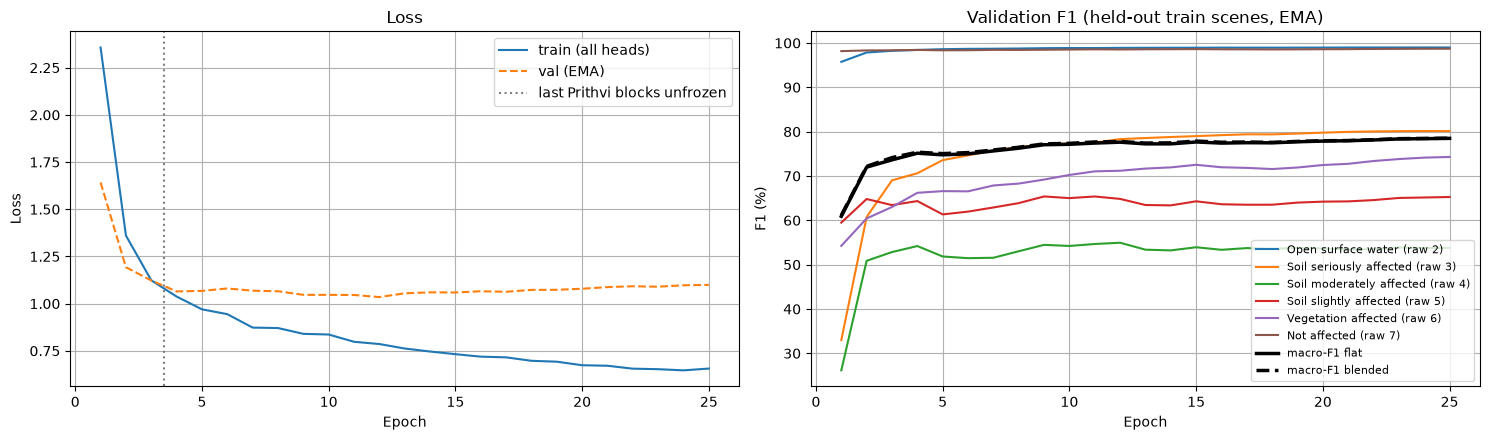

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
ep = np.arange(1, len(history["train_loss"]) + 1)
axes[0].plot(ep, history["train_loss"], label="train (all heads)")
axes[0].plot(ep, history["val_loss"], label="val (EMA)", linestyle="--")
axes[0].axvline(FREEZE_EPOCHS + 0.5, color="gray", linestyle=":", label="last Prithvi blocks unfrozen")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].set_title("Loss"); axes[0].legend(); axes[0].grid(True)
val_f1 = np.array(history["val_f1"])
for k in range(NUM_CLASSES):
    axes[1].plot(ep, 100 * val_f1[:, k], label=CLASS_NAMES[k])
axes[1].plot(ep, 100 * np.array(history["val_macro_f1"]), color="black", linewidth=2.5, label="macro-F1 flat")
axes[1].plot(ep, 100 * np.array(history["val_macro_f1_blend"]), color="black", linewidth=2.5,
             linestyle="--", label="macro-F1 blended")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("F1 (%)"); axes[1].set_title("Validation F1 (held-out train scenes, EMA)")
axes[1].legend(fontsize=8); axes[1].grid(True)
plt.tight_layout()
plt.show()

## 8. Ablation: what do the history and the radar contribute?

The best EMA weights are loaded into the same network and evaluated on the validation patches three ways: normally, with **every Prithvi frame replaced by the target date** (no history), and with the **radar channels of the detail stream zeroed**. These are inference-time ablations (the network was trained with some dropped dates but never with zeroed radar), so read the radar drop as an upper bound on its importance.

In [20]:
load_subset(model, torch.load(BEST_PATH, map_location=device, weights_only=False)["model"])
model.eval()

ablation = {}
for label, kw in [("full model", {}), ("no history (target repeated)", {"no_history": True}),
                  ("Sentinel-1 zeroed", {"no_s1": True})]:
    _, cm_m, cm_b = evaluate_patches(model, val_loader, **kw)
    ablation[label] = {"macro_f1_flat": macro_f1(cm_m), "macro_f1_blend": macro_f1(cm_b),
                       "f1_blend": prf(cm_b)[2].tolist()}

short = ["Water", "Soil serious", "Soil moderate", "Soil slight", "Vegetation", "Not affected"]
print(f"{'Setting':<30}{'flat':>8}{'blend':>8}  " + "".join(f"{s:>15}" for s in short))
for label, r in ablation.items():
    print(f"{label:<30}{100 * r['macro_f1_flat']:>8.2f}{100 * r['macro_f1_blend']:>8.2f}  "
          + "".join(f"{100 * v:>15.2f}" for v in r["f1_blend"]))

Setting                           flat   blend            Water   Soil serious  Soil moderate    Soil slight     Vegetation   Not affected
full model                       78.49   78.53            98.99          80.12          53.78          65.26          74.29          98.71
no history (target repeated)     78.55   78.58            98.99          80.27          53.69          65.39          74.40          98.71
Sentinel-1 zeroed                71.22   70.66            97.96          48.62          60.70          63.86          55.79          97.00


## 9. Full-scene inference, head blending and (conservative) calibration

- Prithvi is built for one fixed image size, so every prediction window is exactly `PATCH = 224` px. Its central `TILE = 160` px is kept and the surrounding `MARGIN = 32` px is discarded, so there are no seams. Windows are processed `INFER_BATCH` at a time; image borders are reflect-padded.
- **Calibration is deliberately conservative**, because it hurt on the test set in notebook 11. Only the held-out training scenes are used. The head-blend weight α is chosen from `{0, 0.25, 0.5, 0.75, 1}`. A per-class logit bias is searched only within **±1.0**, and it is **kept only if it improves held-out macro-F1 by at least 1.0 point**; otherwise the bias is zero.
- The test set is evaluated with three variants side by side, all fitted without any test data: **raw** (flat head), **blend** (α) and **blend + bias**.

In [21]:
def tile_starts(length: int, tile: int):
    starts = list(range(0, max(length - tile, 0) + 1, tile))
    if starts[-1] + tile < length:
        starts.append(length - tile)
    return starts


TTA_OPS = {"none": [(0, False)], "flip": [(0, False), (0, True)],
           "d4": [(k, f) for f in (False, True) for k in range(4)]}[TTA]


def _apply(x, k, flip):
    if flip:
        x = x.flip(-1)
    return torch.rot90(x, k, dims=(-2, -1)) if k else x


def _invert(x, k, flip):
    if k:
        x = torch.rot90(x, -k, dims=(-2, -1))
    return x.flip(-1) if flip else x


@torch.no_grad()
def predict_window(net, b):
    p_main = p_h = 0.0
    for k, flip in TTA_OPS:
        with autocast():
            out = net({key: _apply(v, k, flip) for key, v in b.items()})
        pm, ph = compose_probs(out)
        p_main = p_main + _invert(pm, k, flip)
        p_h = p_h + _invert(ph, k, flip)
    return p_main / len(TTA_OPS), p_h / len(TTA_OPS)


def window_inputs(sc: Scene, r0: int, c0: int):
    ra, rb = max(r0 - MARGIN, 0), min(r0 + TILE + MARGIN, sc.H)
    ca, cb = max(c0 - MARGIN, 0), min(c0 + TILE + MARGIN, sc.W)
    pv, cnn = read_frames(sc, ra, ca, rb - ra, cb - ca)
    top, bottom = MARGIN - (r0 - ra), MARGIN - (rb - r0 - TILE)
    left, right = MARGIN - (c0 - ca), MARGIN - (cb - c0 - TILE)
    pv = np.pad(pv, ((0, 0), (0, 0), (top, bottom), (left, right)), mode="reflect")
    cnn = np.pad(cnn, ((0, 0), (top, bottom), (left, right)), mode="reflect")
    return torch.from_numpy(pv), torch.from_numpy(cnn)


@torch.no_grad()
def scene_probs(net, sc: Scene, max_tiles=None):
    """Yield (r0, c0, p_flat (6,TILE,TILE), p_hier (6,TILE,TILE)) covering the whole scene."""
    net.eval()
    positions = [(r0, c0) for r0 in tile_starts(sc.H, TILE) for c0 in tile_starts(sc.W, TILE)]
    if max_tiles:
        positions = positions[:max_tiles]
    crop = (slice(None), slice(MARGIN, MARGIN + TILE), slice(MARGIN, MARGIN + TILE))
    for i in range(0, len(positions), INFER_BATCH):
        chunk = positions[i:i + INFER_BATCH]
        items = [window_inputs(sc, r0, c0) for r0, c0 in chunk]
        b = {"pv": torch.stack([it[0] for it in items]).to(device),
             "cnn": torch.stack([it[1] for it in items]).to(device)}
        pm, ph = predict_window(net, b)
        for j, (r0, c0) in enumerate(chunk):
            yield r0, c0, pm[j][crop].cpu().numpy(), ph[j][crop].cpu().numpy()


def blend_logp(pm, ph, alpha):
    return np.log((1 - alpha) * pm + alpha * ph + 1e-8)


def fit_logit_bias(logp: np.ndarray, y: np.ndarray, rounds: int = 3, limit: float = 1.0):
    grid = np.arange(-limit, limit + 1e-6, 0.25, dtype=np.float32)
    bias = np.zeros(NUM_CLASSES, dtype=np.float32)
    best_s = macro_f1(confusion(y, logp.argmax(1)))
    for _ in range(rounds):
        for k in range(NUM_CLASSES):
            for v in grid:
                trial = bias.copy()
                trial[k] = v
                s = macro_f1(confusion(y, (logp + trial).argmax(1)))
                if s > best_s + 1e-6:
                    best_s, bias = s, trial
    return bias, best_s


rng = np.random.default_rng(SEED)
cal_pm, cal_ph, cal_y = [], [], []
for sc in val_scenes:
    t0 = time.time()
    for r0, c0, pm, ph in scene_probs(model, sc, MAX_TILES):
        y = sc.gt[r0:r0 + TILE, c0:c0 + TILE]
        take = (y != IGNORE) & (rng.random(y.shape) < 0.05)
        cal_pm.append(pm[:, take].T); cal_ph.append(ph[:, take].T); cal_y.append(y[take])
    print(f"  {sc.name}: inference {(time.time() - t0) / 60:.1f} min")
cal_pm = np.concatenate(cal_pm).astype(np.float32)
cal_ph = np.concatenate(cal_ph).astype(np.float32)
cal_y = np.concatenate(cal_y)
print(f"Calibration sample: {len(cal_y):,} pixels")

raw_score = macro_f1(confusion(cal_y, cal_pm.argmax(1)))
alpha_scores = {a: macro_f1(confusion(cal_y, blend_logp(cal_pm, cal_ph, a).argmax(1)))
                for a in (0.0, 0.25, 0.5, 0.75, 1.0)}
ALPHA = max(alpha_scores, key=alpha_scores.get)
print(f"Held-out macro-F1: raw flat head {100 * raw_score:.2f} | by blend alpha "
      f"{ {a: round(100 * s, 2) for a, s in alpha_scores.items()} } -> alpha = {ALPHA}")

cand_bias, cand_score = fit_logit_bias(blend_logp(cal_pm, cal_ph, ALPHA), cal_y)
if cand_score - alpha_scores[ALPHA] >= 0.01:
    logit_bias = cand_bias
    print(f"Logit bias kept: held-out {100 * alpha_scores[ALPHA]:.2f} -> {100 * cand_score:.2f}  {np.round(logit_bias, 2).tolist()}")
else:
    logit_bias = np.zeros(NUM_CLASSES, dtype=np.float32)
    print(f"Logit bias NOT used: gain {100 * (cand_score - alpha_scores[ALPHA]):.2f} points is below the 1.0-point threshold")
CAL_PATH.write_text(json.dumps({"alpha": ALPHA, "logit_bias": logit_bias.tolist(),
                                "alpha_scores": {str(a): s for a, s in alpha_scores.items()},
                                "class_names": CLASS_NAMES}, indent=2))
del cal_pm, cal_ph, cal_y

  BNPI_20230208: inference 3.0 min
  KNPI_20220310: inference 1.6 min
Calibration sample: 1,576,722 pixels
Held-out macro-F1: raw flat head 79.08 | by blend alpha {0.0: 79.08, 0.25: 79.16, 0.5: 79.21, 0.75: 79.19, 1.0: 79.13} -> alpha = 0.5
Logit bias kept: held-out 79.21 -> 80.51  [-0.25, -0.75, -1.0, -0.5, 0.5, 1.0]


## 10. Evaluation on the 9 test scenes

Three rows: **raw** (flat head, plain argmax), **blend** (flat + hierarchical heads at the held-out α) and **blend + bias** (the above plus the held-out logit bias, which may be zero). Predicted label maps are saved to `outputs/preds_prithvi/`. The comparison table uses the real test results of notebooks 10 and 11.

In [22]:
test_scenes = all_test[:2] if QUICK_TEST else all_test

cm_raw = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
cm_blend = np.zeros_like(cm_raw)
cm_cal = np.zeros_like(cm_raw)
pred_maps, per_scene = {}, {}
for sc in test_scenes:
    t0 = time.time()
    p_raw = np.full((sc.H, sc.W), IGNORE, dtype=np.uint8)
    p_blend = np.full((sc.H, sc.W), IGNORE, dtype=np.uint8)
    p_cal = np.full((sc.H, sc.W), IGNORE, dtype=np.uint8)
    for r0, c0, pm, ph in scene_probs(model, sc, MAX_TILES):
        sl = (slice(r0, r0 + TILE), slice(c0, c0 + TILE))
        lp = blend_logp(pm, ph, ALPHA)
        p_raw[sl] = pm.argmax(0)
        p_blend[sl] = lp.argmax(0)
        p_cal[sl] = (lp + logit_bias[:, None, None]).argmax(0)
    cm_raw += confusion(sc.gt, p_raw)
    cm_blend += confusion(sc.gt, p_blend)
    cm_scene = confusion(sc.gt, p_cal)
    cm_cal += cm_scene
    pred_maps[sc.name] = p_cal
    np.save(PRED_DIR / f"{sc.name}.npy", np.stack([p_raw, p_blend, p_cal]))
    per_scene[sc.name] = {"macro_f1": macro_f1(cm_scene), "f1": prf(cm_scene)[2].tolist(),
                          "earlier_dates": len(CONTEXT[sc.name])}
    print(f"  {sc.name}: {(time.time() - t0) / 60:.1f} min | earlier dates {len(CONTEXT[sc.name])} | "
          f"scene macro-F1 {100 * macro_f1(cm_scene):.2f}")

res_raw = report(cm_raw, "TEST SET - Prithvi-EO-2.0 + UPerNet, flat head, raw argmax")
res_blend = report(cm_blend, f"TEST SET - Prithvi-EO-2.0 + UPerNet, blended heads (alpha={ALPHA})")
res_cal = report(cm_cal, "TEST SET - Prithvi-EO-2.0 + UPerNet, blended heads + held-out logit bias")

columns = {   # real test results of the earlier notebooks (per-class F1, macro-F1, pixel-weighted F1 raw 2-6)
    "NB10 cal": ([98.62, 71.04, 60.20, 63.54, 67.22, 98.56], 76.53, 81.53),
    "NB11 raw": ([98.68, 70.04, 61.82, 56.80, 67.86, 98.31], 75.59, 80.30),
    "NB11 cal": ([98.40, 67.43, 57.77, 56.44, 64.18, 98.41], 73.77, 79.00),
}
for label, r in (("NB13 raw", res_raw), ("NB13 blend", res_blend), ("NB13 +bias", res_cal)):
    columns[label] = ([100 * v for v in r["f1"]], 100 * r["macro_f1_all"], 100 * r["weighted_water"][2])

print("\nPer-class F1 (%) on the test set")
print(f"{'Class':<36}" + "".join(f"{c:>12}" for c in columns))
for k in range(NUM_CLASSES):
    print(f"{CLASS_NAMES[k]:<36}" + "".join(f"{v[0][k]:>12.2f}" for v in columns.values()))
print(f"{'MACRO-F1 (6 classes)':<36}" + "".join(f"{v[1]:>12.2f}" for v in columns.values()))
print(f"{'Pixel-weighted F1, raw 2-6':<36}" + "".join(f"{v[2]:>12.2f}" for v in columns.values()))
print("Paper Table 1 best (RUPNet), pixel-weighted F1 raw 2-6: 81.19")

RESULTS_PATH.write_text(json.dumps({
    "model": "Prithvi-EO-2.0 + UPerNet (notebook 13)", "quick_test": QUICK_TEST, "backbone": BACKBONE,
    "alpha": ALPHA, "logit_bias": logit_bias.tolist(), "test_raw": res_raw, "test_blend": res_blend,
    "test_calibrated": res_cal, "per_scene": per_scene, "val_ablation": ablation, "best_val_macro_f1": best_score,
    "confusion_calibrated": cm_cal.tolist(),
    "config": {**run_cfg, "tta": TTA, "tile": TILE, "margin": MARGIN},
}, indent=2))
print(f"\nSaved all numbers -> {RESULTS_PATH}")

  BNPI_20220208: 3.1 min | earlier dates 0 | scene macro-F1 80.38
  BNPI_20220325: 2.7 min | earlier dates 1 | scene macro-F1 77.92
  BNPI_20231125: 3.1 min | earlier dates 0 | scene macro-F1 67.79
  BNPI_20240129: 2.8 min | earlier dates 2 | scene macro-F1 82.03
  KNPI_20230213: 1.8 min | earlier dates 0 | scene macro-F1 79.56
  KNPI_20230603: 1.6 min | earlier dates 1 | scene macro-F1 67.40
  KNPI_20240104: 1.8 min | earlier dates 0 | scene macro-F1 73.55
  KNPI_20240129: 1.6 min | earlier dates 1 | scene macro-F1 66.56
  KNPI_20240203: 1.6 min | earlier dates 2 | scene macro-F1 77.53

TEST SET - Prithvi-EO-2.0 + UPerNet, flat head, raw argmax
Cls Name                                   Pr (%)   Rc (%)   F1 (%)          Pixels
--------------------------------------------------------------------------------------
0   Open surface water (raw 2)              98.78    97.98    98.38       4,774,539
1   Soil seriously affected (raw 3)         64.09    71.16    67.44         313,249
2   Soi

## 11. Confusion matrix

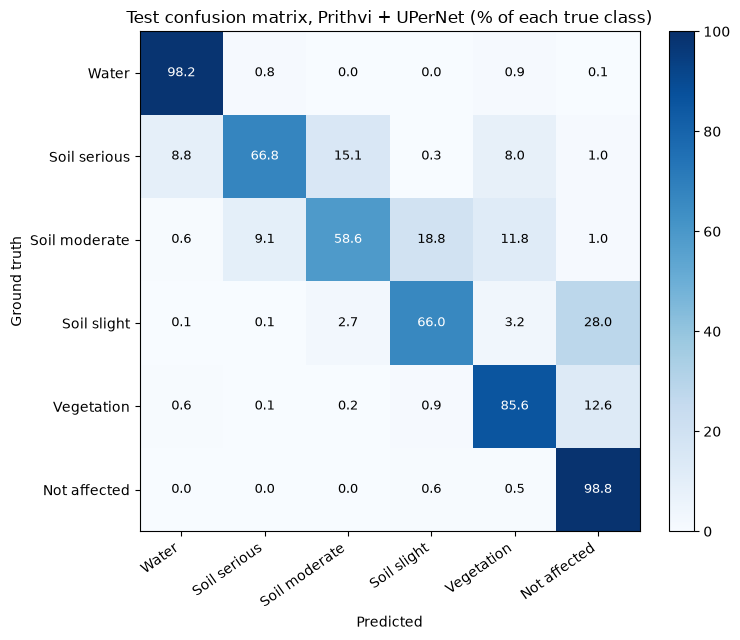

In [23]:
cm_pct = 100 * cm_cal / np.maximum(cm_cal.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(short, rotation=35, ha="right")
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(short)
ax.set_xlabel("Predicted"); ax.set_ylabel("Ground truth")
ax.set_title("Test confusion matrix, Prithvi + UPerNet (% of each true class)")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{cm_pct[i, j]:.1f}", ha="center", va="center",
                color="white" if cm_pct[i, j] > 55 else "black", fontsize=9)
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

## 12. Prediction maps

For up to three test scenes, the 512×512 window richest in affected soil is shown three ways: true colour, ground truth and the prediction.

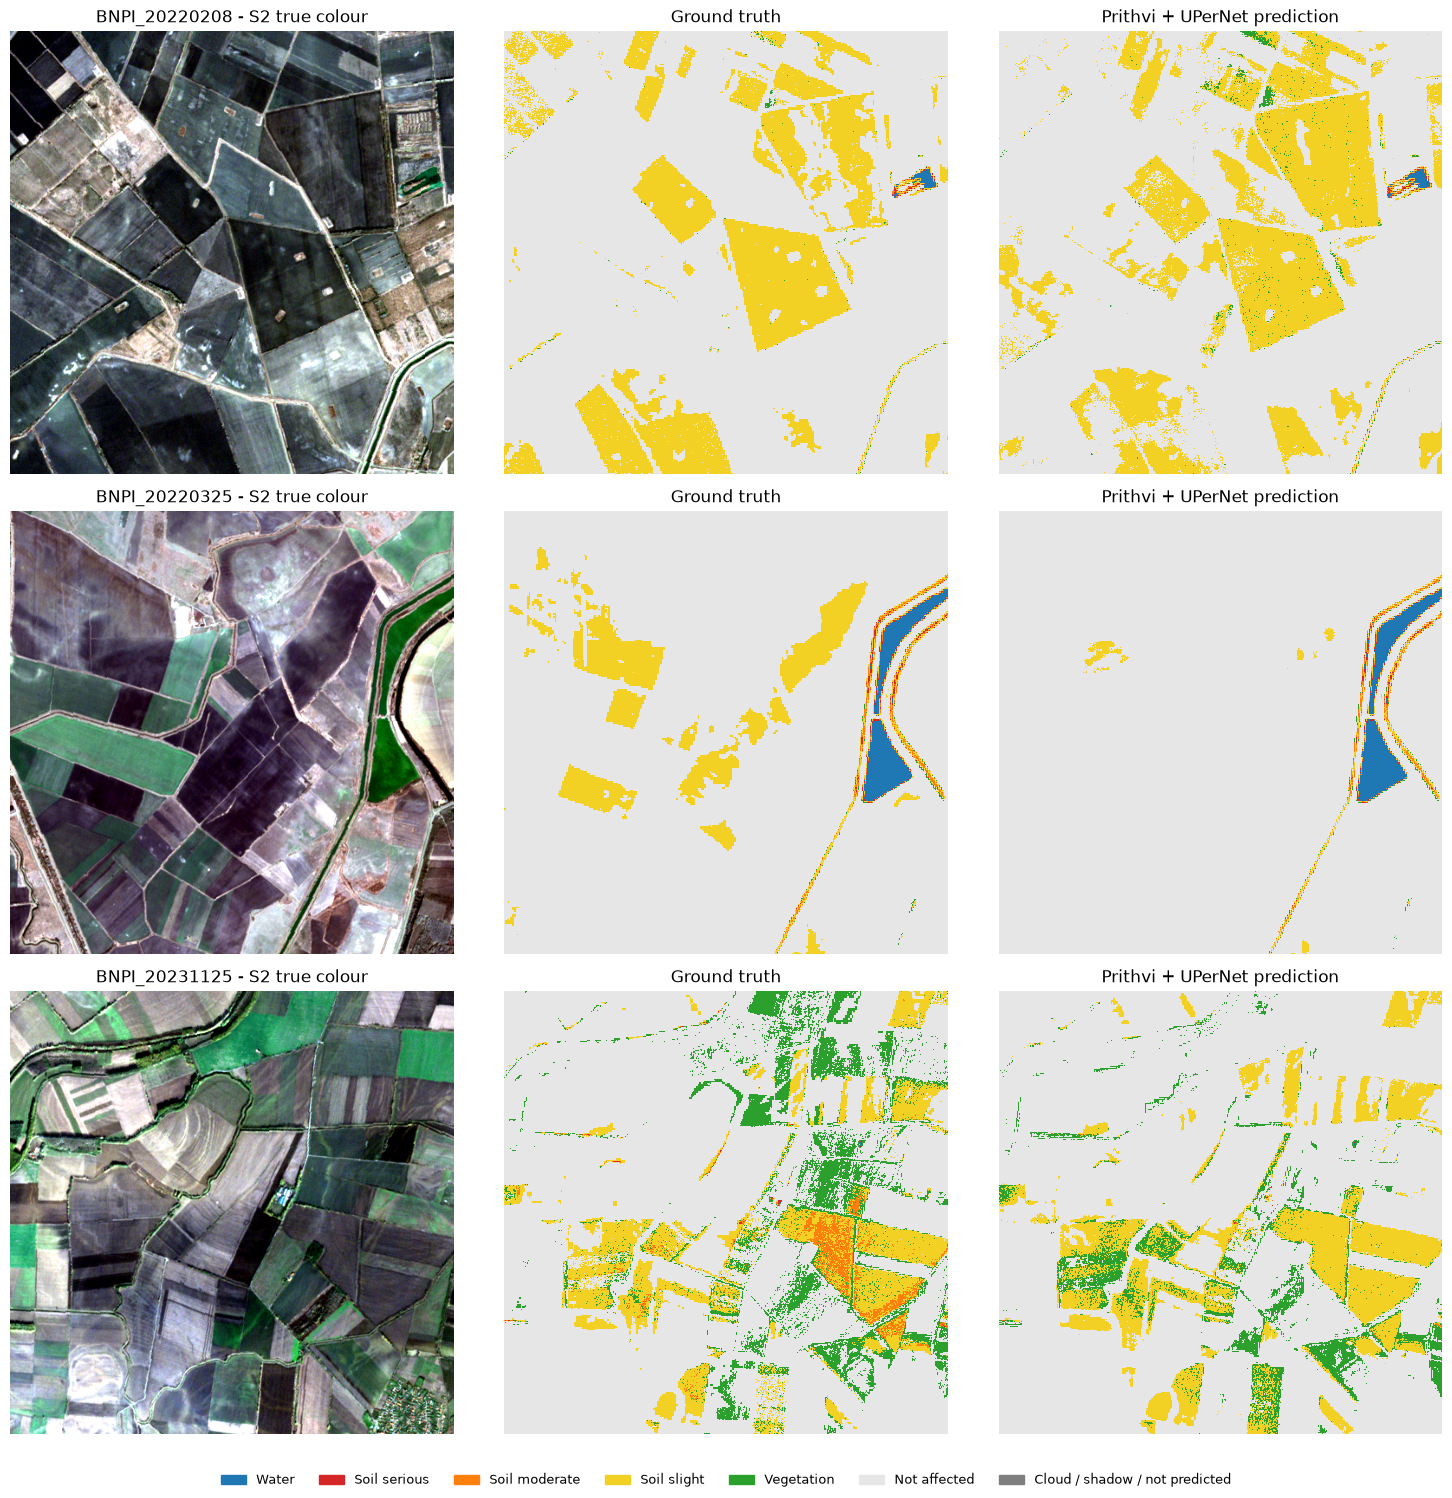

In [24]:
PALETTE = ["#1f77b4", "#d62728", "#ff7f0e", "#f2d024", "#2ca02c", "#e6e6e6", "#7f7f7f"]
cmap = ListedColormap(PALETTE)


def to_display(label_map: np.ndarray) -> np.ndarray:
    return np.where(label_map == IGNORE, NUM_CLASSES, label_map)


def stretch_rgb(rgb: np.ndarray) -> np.ndarray:
    out = np.empty_like(rgb, dtype=np.float32)
    for k in range(3):
        lo, hi = np.percentile(rgb[..., k], [2, 98])
        out[..., k] = np.clip((rgb[..., k] - lo) / (hi - lo + 1e-8), 0, 1)
    return out


shown = [sc for sc in test_scenes if sc.name in pred_maps][:3]
fig, axes = plt.subplots(len(shown), 3, figsize=(15, 5 * len(shown)), squeeze=False)
for row, sc in enumerate(shown):
    pred = pred_maps[sc.name]
    block = 256
    soil = ((sc.gt >= 1) & (sc.gt <= 3)) & (pred != IGNORE)
    hb, wb = sc.H // block, sc.W // block
    counts = soil[:hb * block, :wb * block].reshape(hb, block, wb, block).sum((1, 3))
    bi, bj = np.unravel_index(counts.argmax(), counts.shape)
    r0 = int(np.clip(bi * block - 128, 0, sc.H - 512))
    c0 = int(np.clip(bj * block - 128, 0, sc.W - 512))
    s2, _ = sc.read(r0, c0, 512, 512)
    axes[row, 0].imshow(stretch_rgb(np.stack([s2[3], s2[2], s2[1]], -1).astype(np.float32)))
    axes[row, 0].set_title(f"{sc.name} - S2 true colour")
    axes[row, 1].imshow(to_display(sc.gt[r0:r0 + 512, c0:c0 + 512]), cmap=cmap, vmin=0, vmax=NUM_CLASSES,
                        interpolation="nearest")
    axes[row, 1].set_title("Ground truth")
    axes[row, 2].imshow(to_display(pred[r0:r0 + 512, c0:c0 + 512]), cmap=cmap, vmin=0, vmax=NUM_CLASSES,
                        interpolation="nearest")
    axes[row, 2].set_title("Prithvi + UPerNet prediction")
    for a in axes[row]:
        a.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=PALETTE[k]) for k in range(NUM_CLASSES + 1)]
fig.legend(handles, short + ["Cloud / shadow / not predicted"], loc="lower center", ncol=7, fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

## 13. Summary: fill in after running

| Test set | NB10 (cal) | NB11 (raw) | NB13 raw | NB13 blend | NB13 + bias |
|---|---|---|---|---|---|
| Water F1 | 98.62 | 98.68 | | | |
| Soil seriously affected F1 | 71.04 | 70.04 | | | |
| Soil moderately affected F1 | 60.20 | 61.82 | | | |
| Soil slightly affected F1 | 63.54 | 56.80 | | | |
| Vegetation affected F1 | 67.22 | 67.86 | | | |
| Not affected F1 | 98.56 | 98.31 | | | |
| Macro-F1 (6 classes) | 76.53 | 75.59 | | | |
| Pixel-weighted F1, raw 2–6 (paper: 81.19) | 81.53 | 80.30 | | | |

**Ablation (§8, validation):** full ___ / no history ___ / Sentinel-1 zeroed ___

**Settings to report:** backbone variant, number of unfrozen blocks, TTA mode, α, whether the bias was used, GPU and wall-clock time (all saved in `outputs/prithvi_results.json`).

**How to read the result.** If this notebook ties notebooks 10 and 11 again, that is strong evidence the limit is the labels (fuzzy serious/moderate/slight boundaries, per-scene differences), not the model. That is a legitimate finding for the report. The most promising remaining steps are then: (1) averaging this model's probabilities with notebook 10's (their errors differ); (2) evaluating with a metric that tolerates adjacent-grade confusions (for example SplitClass-style dual labels, as the paper does); (3) re-checking how consistent the ground-truth labels are on the worst test scenes (KNPI_20240104, BNPI_20231125).